In [152]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [153]:
# run_path = "runs/CAT-v0__greedy__42__1741124294"
# path = os.path.join(run_path, "results.npz")

# from dqn import Args  # just for the exp_name so doesn't matter which Args we import
# data = np.load(path, allow_pickle=True)

# # thetas = data["thetas"]
# # true_thetas = data["true_thetas"]
# args = data["args"]

In [154]:
def scatter_plots(datasets):
    num_datasets = len(datasets)
    rows = 2
    cols = (num_datasets + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6 * rows))
    fig.suptitle("Thetas vs True Thetas")
    axes = axes.flatten() if num_datasets > 1 else [axes]
    
    for ax, dataset in zip(axes, datasets):
        title = dataset["args"].item().exp_name
        values_x = dataset["thetas"]
        values_y = dataset["true_thetas"]
        sns.scatterplot(x=values_x.ravel(), y=values_y.ravel(), ax=ax)
        ax.set_xlabel("Thetas")
        ax.set_ylabel("True Thetas")
        ax.set_title(title)
    
    for ax in axes[num_datasets:]:
        ax.set_visible(False)
    
    plt.tight_layout()
    plt.show()

def violin_plots(datasets):
    all_data = []
    for dataset in datasets:
        exp_name = dataset["args"].item().exp_name
        residuals = (dataset["true_thetas"] - dataset["thetas"]).ravel()
        for r in residuals:
            all_data.append({"exp_name": exp_name, "residual": r})
    df = pd.DataFrame(all_data)
    sns.violinplot(x="exp_name", y="residual", data=df)
    plt.xticks(rotation=90)
    plt.title("Violin Plots of Residuals")
    plt.show()


In [ ]:
from dqn import Args  # just for the exp_name so doesn't matter which Args we import
import glob

# Automatically find the newest runs for each experiment
# Extract patterns from the runs up to "students__"
experiments = [
    "runs/CAT-v0__greedy_time_aware_1000_students",
    "runs/CAT-v0__greedy_1000_students",
    "runs/CAT-v0__dqn_mask_500000_train_steps_1000_students",
    "runs/CAT-v0__dqn_include_answered_500000_train_steps_1000_students",
    "runs/CAT-v0__dqn_500000_train_steps_1000_students",
]

# Example dir name: runs/CAT-v0__dqn__42__1741128491
# Find the newest run for each pattern
runs = []
for pattern in experiments:
    matching_dirs = [d for d in glob.glob(pattern + "*") if os.path.isdir(d)]
    if matching_dirs:
        # Sort by timestamp (last part of the directory name)
        matching_dirs.sort(key=lambda x: int(x.split("__")[-1]), reverse=True)
        # Add the directory with the largest timestamp
        runs.append(matching_dirs[0])
datasets = [np.load(os.path.join(run, "results.npz"), allow_pickle=True) for run in runs]

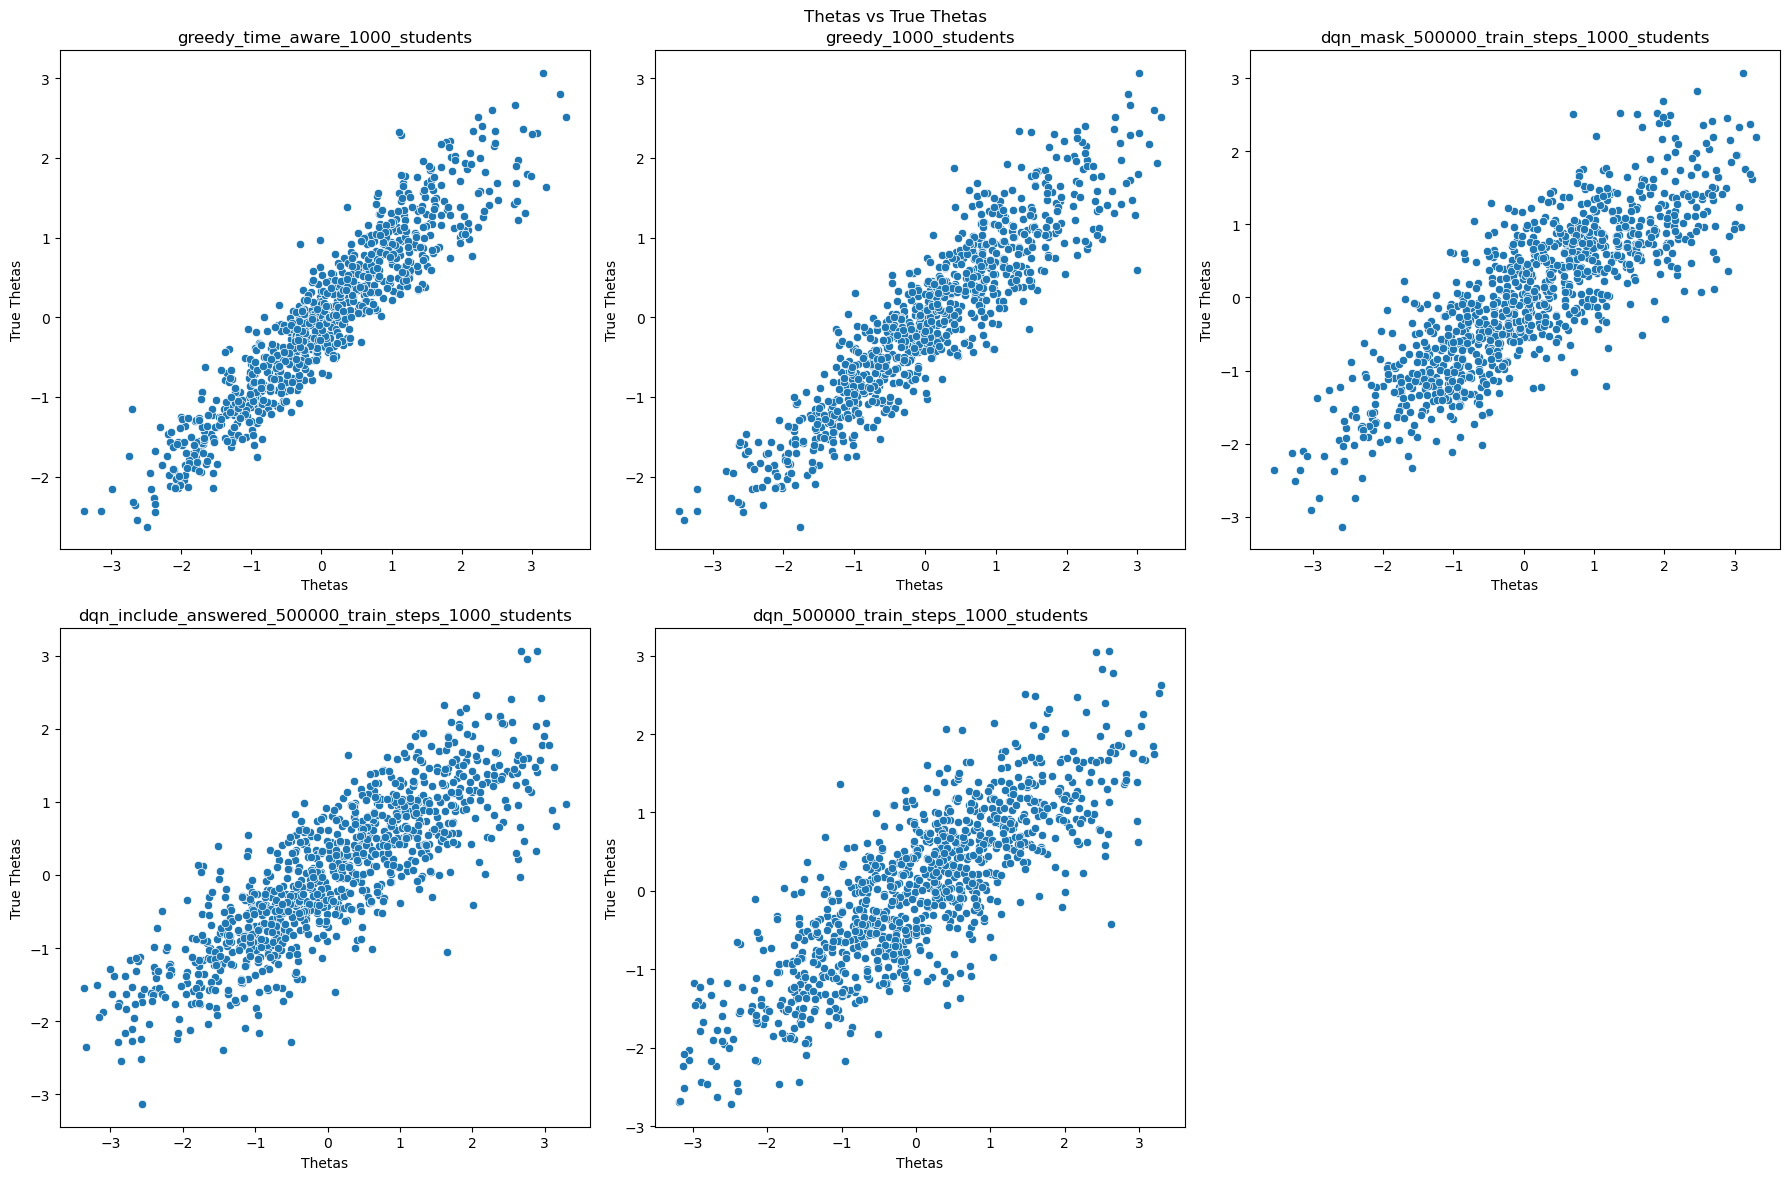

In [156]:
scatter_plots(datasets)

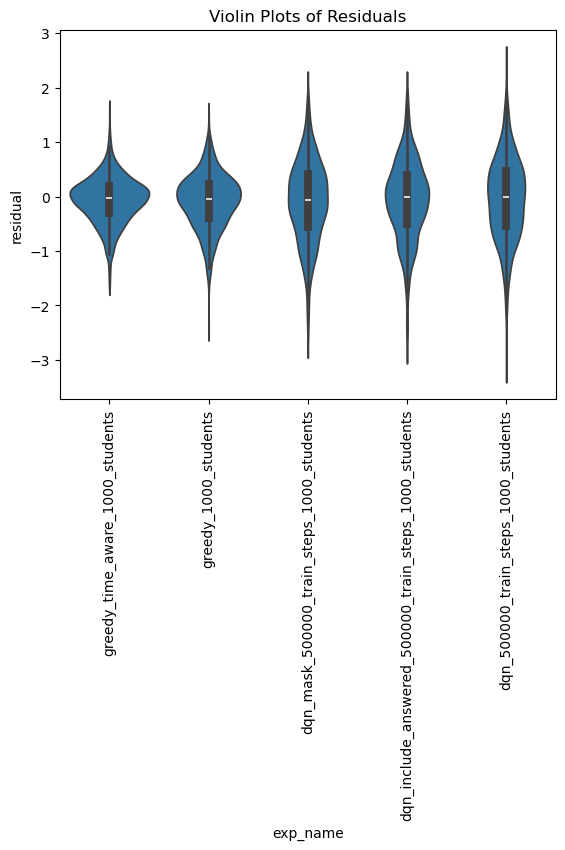

In [157]:
violin_plots(datasets)

In [158]:
for dataset in datasets:
    print(f"Dataset: {dataset['args'].item().exp_name}")
    print(f"RMSE: {np.sqrt(np.mean((dataset['thetas'] - dataset['true_thetas']) ** 2))}")

Dataset: greedy_time_aware_1000_students
RMSE: 0.42455431243647107
Dataset: greedy_1000_students
RMSE: 0.503505781485483
Dataset: dqn_mask_500000_train_steps_1000_students
RMSE: 0.7482167138226179
Dataset: dqn_include_answered_500000_train_steps_1000_students
RMSE: 0.7286696128799687
Dataset: dqn_500000_train_steps_1000_students
RMSE: 0.7465441841930914


In [6]:
import plotly.graph_objects as go
import pandas as pd

def sankey_from_action_sequences(sequences, min_frequency=1, max_depth=None):
    """
    Generates a Sankey diagram from a list of action sequences, with depth control.

    Args:
        sequences: A list of lists, where each inner list represents a sequence
                   of actions (represented by IDs, strings, or any hashable type).
        min_frequency: Minimum number of times a link must appear to be included.
        max_depth: The maximum depth (number of steps from the start) to visualize.
                   If None, all steps are included.

    Returns:
        A plotly.graph_objects.Figure object representing the Sankey diagram.
    """

    links = []
    for sequence in sequences:
        for i in range(len(sequence) - 1):
            if max_depth is None or i < max_depth:
                source_label = f"Q{sequence[i]}-#{i}"  # Add depth to source
                target_label = f"Q{sequence[i+1]}-#{i+1}" # Add depth to target
                links.append((source_label, target_label))


    df = pd.DataFrame(links, columns=['source', 'target'])
    link_counts = df.groupby(['source', 'target']).size().reset_index(name='value')
    link_counts = link_counts[link_counts['value'] >= min_frequency]

    all_nodes = list(link_counts['source'].unique()) + list(link_counts['target'].unique())
    all_nodes = sorted(list(set(all_nodes)))
    node_labels = [str(node) for node in all_nodes]
    label_to_index = {label: i for i, label in enumerate(node_labels)}

    link_counts['source_index'] = link_counts['source'].map(label_to_index)
    link_counts['target_index'] = link_counts['target'].map(label_to_index)

    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=node_labels,
        ),
        link=dict(
            source=link_counts['source_index'],
            target=link_counts['target_index'],
            value=link_counts['value'],
        )
    )])

    fig.update_layout(title_text="Action Sequence Sankey Diagram", font_size=12)
    return fig

In [7]:
example_sequences = [
    [1, 2, 3, 4, 5],
    [1, 2, 4, 5],
    [1, 3, 4, 1],
    [1, 3, 4, 5],
    [2, 3, 5],
    [1, 2, 3, 1, 2, 4, 5],
    [1, 3, 2, 4, 1, 2, 5],
    [1, 1, 1, 2, 2, 4, 4, 5, 5],
]

# --- Sankey with Depth Control ---
fig2 = sankey_from_action_sequences(example_sequences, min_frequency=1, max_depth=3) # Limiting to depth 3
fig2.show()

fig3 = sankey_from_action_sequences(example_sequences, min_frequency=2, max_depth=2) # Limiting to depth 2, min frequency 2
fig3.show()